t‑SNE: нелинейное вложение, оптимизирует дивергенцию Кульбака–Лейблера между распределениями близостей точек, хорошо показывает локальные кластеры, но медленно, плохо сохраняет глобальные расстояния, чувствительно к perplexity и random_state.

UMAP: основан на теории многобразий и топологии, строит взвешенный граф соседей и оптимизирует кросс‑энтропию; быстрее t‑SNE, лучше сохраняет глобальную структуру, более устойчив к малым изменениям параметров (n_neighbors, min_dist).

TriMAP: ориентирован на сохранение глобальной структуры через тройки точек (anchor, сосед, далёкий), улучшает глобальное расположение кластеров при сохранении локальной структуры.

PaCMAP: управляет соотношением близких, средних и далёких пар, чтобы одновременно хорошо держать локальные кластеры и общую форму; показывает хорошие результаты на омикс‑данных и эмбеддингах.

PHATE: использует диффузионные процессы и потенциал для визуализации непрерывных траекторий (например, дифференцировка клеток), хорошо показывает как кластеры, так и переходы между ними.



In [94]:
%pip install umap-learn trimap pacmap phate scikit-learn seaborn

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

from sklearn.manifold import TSNE
import umap
import trimap
import pacmap
import phate



In [96]:
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
feature_names_iris = iris.feature_names
print(X_iris.shape, np.unique(y_iris))


(150, 4) [0 1 2]


In [97]:
from google.colab import drive
drive.mount('/content/drive')

path = "/content/drive/MyDrive/MAGA/clustering_(2_semestr)/practice/phones_usage.csv"
df = pd.read_csv(path)
df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,transaction_id,user_id,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,stress_level,academic_work_impact,addiction_level,addicted_label
0,TXN00001,U00001,21,Male,3.23,2.01,0.89,4.55,7.55,248,154,3.95,Medium,Yes,NaN,0
1,TXN00002,U00002,24,Other,5.09,3.81,2.24,4.44,7.66,127,71,6.71,Medium,Yes,NaN,0
2,TXN00003,U00003,31,Other,6.06,1.36,3.83,2.35,4.92,44,106,8.68,High,No,Mild,0
3,TXN00004,U00004,32,Other,7.83,5.85,1.51,3.54,8.23,178,107,9.77,High,Yes,Moderate,1
4,TXN00005,U00005,25,Male,9.96,5.92,3.42,5.27,6.21,136,177,12.55,Low,No,Severe,1


In [98]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   transaction_id           7500 non-null   object 
 1   user_id                  7500 non-null   object 
 2   age                      7500 non-null   int64  
 3   gender                   7500 non-null   object 
 4   daily_screen_time_hours  7500 non-null   float64
 5   social_media_hours       7500 non-null   float64
 6   gaming_hours             7500 non-null   float64
 7   work_study_hours         7500 non-null   float64
 8   sleep_hours              7500 non-null   float64
 9   notifications_per_day    7500 non-null   int64  
 10  app_opens_per_day        7500 non-null   int64  
 11  weekend_screen_time      7500 non-null   float64
 12  stress_level             7500 non-null   object 
 13  academic_work_impact     7500 non-null   object 
 14  addiction_level         

In [99]:
df['addiction_level'].fillna('Mild', inplace=True)

/tmp/ipykernel_1283/249691183.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['addiction_level'].fillna('Mild', inplace=True)


In [100]:
# удаление столбца с полом человека, т.к. присутствуют значения "Other", которые невозможно закодировать
print(df['gender'].unique())
df = df.drop('gender', axis=1)

['Male' 'Other' 'Female']


In [101]:
stress_map = {'Low': 0, 'Medium': 1, 'High': 2}
df['stress_map'] = df['stress_level'].map(stress_map)

addiction_level_map = {'Mild': 0, 'Moderate': 1, 'Severe': 2}
df['addiction_level_map'] = df['addiction_level'].map(addiction_level_map)

In [102]:
df = df.drop(['transaction_id', 'user_id', 'stress_level', 'academic_work_impact', 'addiction_level'], axis=1)

In [103]:
# целевая переменная - "addicted_label" (наличие зависимости от телефона)
feature_cols = [c for c in df.columns if c != "addicted_label"]
X_own = df[feature_cols].values
y_own = df["addicted_label"].values
print(X_own.shape, len(np.unique(y_own)))


(7500, 11) 2


In [104]:
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)
X_own_scaled = scaler_iris.fit_transform(X_own)

Функции для DR и оценки разделения

In [105]:
def run_tsne(X, random_state=42, perplexity=30, learning_rate=200, n_iter=1000):
    tsne = TSNE(
        perplexity=perplexity, random_state=random_state, learning_rate=learning_rate, n_components=2, max_iter=n_iter
    )
    return tsne.fit_transform(X)

def run_umap(X, random_state=42, n_neighbors=15, min_dist=0.1):
    reducer = umap.UMAP(n_components=2, random_state=random_state, n_neighbors=n_neighbors, min_dist=min_dist)
    return reducer.fit_transform(X)

def run_trimap(X, random_state=42, n_inliers=10, n_outliers=5):
    reducer = trimap.TRIMAP(n_inliers=n_inliers, n_outliers=n_outliers, n_dims=2)
    return reducer.fit_transform(X)

def run_pacmap(X, random_state=42, n_neighbors=10):
    reducer = pacmap.PaCMAP(n_components=2, random_state=random_state, n_neighbors=n_neighbors)
    return reducer.fit_transform(X)

def run_phate(X, random_state=42, knn=15):
    phate_op = phate.PHATE(n_components=2, random_state=random_state, knn=knn)
    return phate_op.fit_transform(X)


Функция оценки качества разделения

In [106]:
def separation_score(X_2d, y):
    D = pairwise_distances(X_2d)
    same = D[y[:, None] == y[None, :]]
    diff = D[y[:, None] != y[None, :]]
    return same.mean(), diff.mean(), diff.mean() / same.mean()


In [107]:
# Отрисовка

def plot_embedding(X_2d, y, title):
    plt.figure(figsize=(6, 5))
    sns.scatterplot(
        x=X_2d[:, 0],
        y=X_2d[:, 1],
        hue=y,
        palette="tab10",
        s=30,
        legend="full"
    )
    plt.title(title)
    plt.xticks([])
    plt.yticks([])
    plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.01 seconds.
    Calculating affinities...
    Calculated affinities in 0.02 seconds.
  Calculated graph and diffusion operator in 0.08 seconds.
  Calculating optimal t...


/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    Automatically selected t = 22
  Calculated optimal t in 0.77 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.02 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 1.94 seconds.
Calculated PHATE in 2.88 seconds.


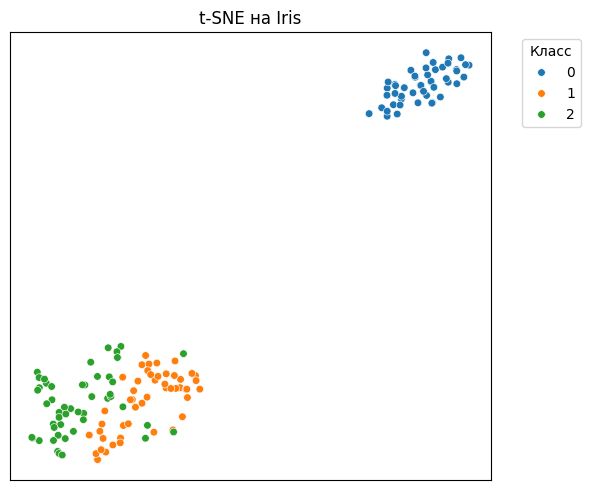

t-SNE: внутрикласс.=3.512, межкласс.=22.740, ratio=6.475


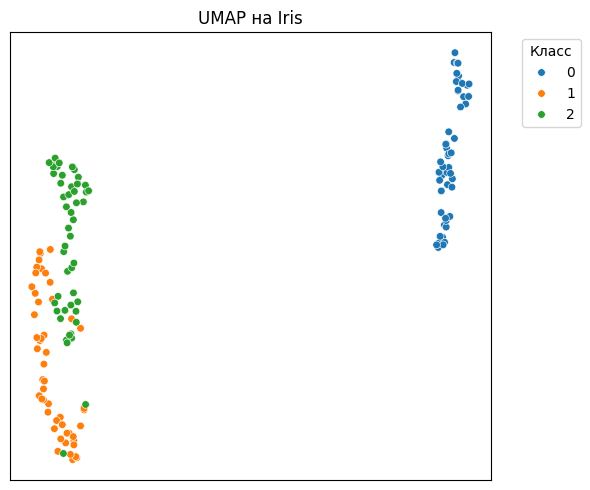

UMAP: внутрикласс.=1.836, межкласс.=14.357, ratio=7.818


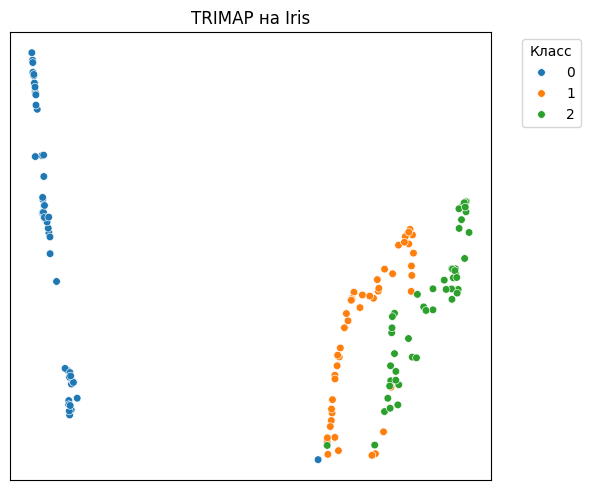

TRIMAP: внутрикласс.=10.981, межкласс.=61.645, ratio=5.614


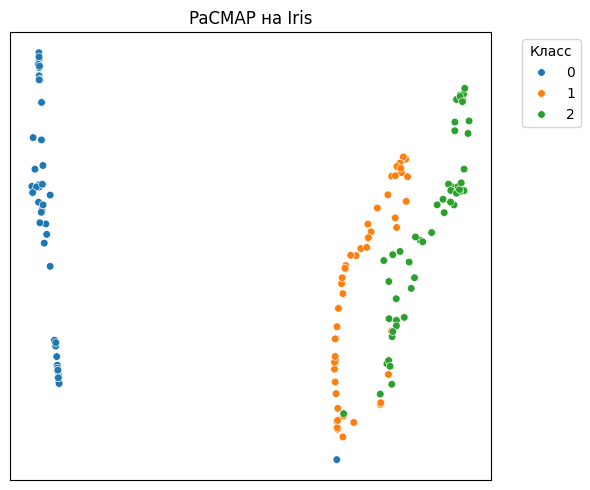

PaCMAP: внутрикласс.=3.470, межкласс.=17.674, ratio=5.093


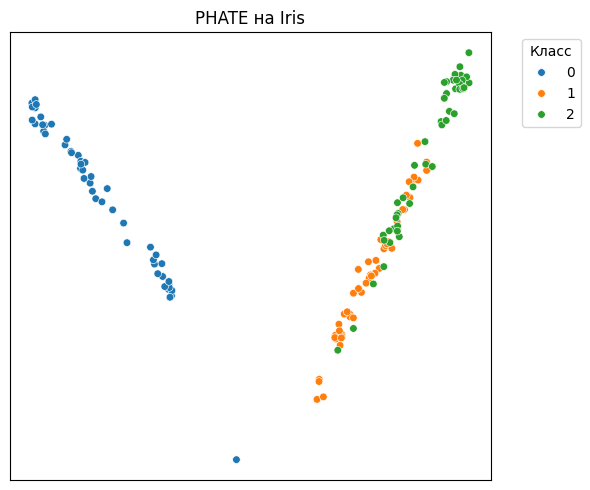

PHATE: внутрикласс.=0.026, межкласс.=0.121, ratio=4.610


In [108]:
X_list = []
names = []

X_tsne_iris = run_tsne(X_iris_scaled, random_state=42)
X_list.append(X_tsne_iris); names.append("t-SNE")

X_umap_iris = run_umap(X_iris_scaled, random_state=42)
X_list.append(X_umap_iris); names.append("UMAP")

X_trimap_iris = run_trimap(X_iris_scaled)
X_list.append(X_trimap_iris); names.append("TRIMAP")

X_pacmap_iris = run_pacmap(X_iris_scaled, random_state=42)
X_list.append(X_pacmap_iris); names.append("PaCMAP")

X_phate_iris = run_phate(X_iris_scaled, random_state=42)
X_list.append(X_phate_iris); names.append("PHATE")

for X_emb, name in zip(X_list, names):
    plot_embedding(X_emb, y_iris, f"{name} на Iris")
    same, diff, ratio = separation_score(X_emb, y_iris)
    print(
        f"{name}: внутрикласс.={same:.3f}, межкласс.={diff:.3f}, ratio={ratio:.3f}"
    )


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Calculating PHATE...
  Running PHATE on 7500 observations and 11 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 2.56 seconds.
    Calculating affinities...
    Calculated affinities in 0.50 seconds.
  Calculated graph and diffusion operator in 3.10 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 1.94 seconds.
    Calculating KMeans...
    Calculated KMeans in 9.48 seconds.
  Calculated landmark operator in 11.43 seconds.
  Calculating optimal t...
    Automatically selected t = 15
  Calculated optimal t in 8.80 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 3.17 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 6.48 seconds.
Calculated PHATE in 34.26 seconds.


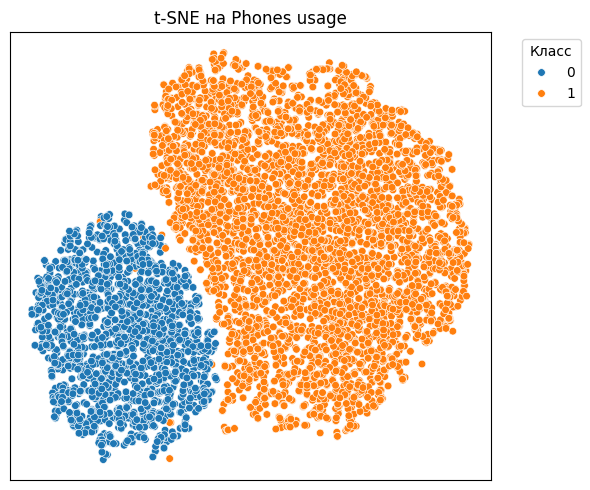

t-SNE: внутрикласс.=50.922, межкласс.=91.600, ratio=1.799


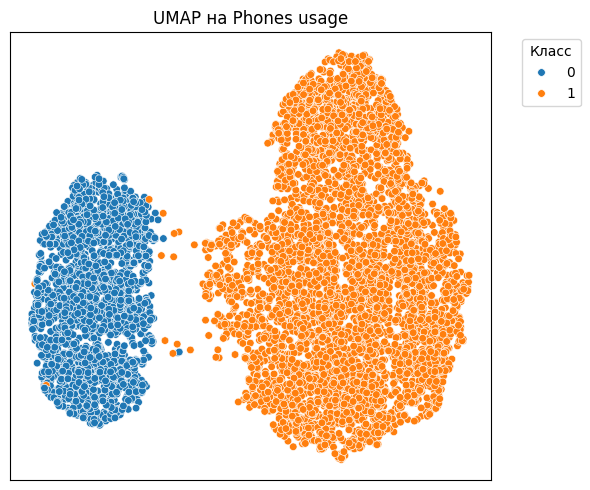

UMAP: внутрикласс.=2.657, межкласс.=6.726, ratio=2.531


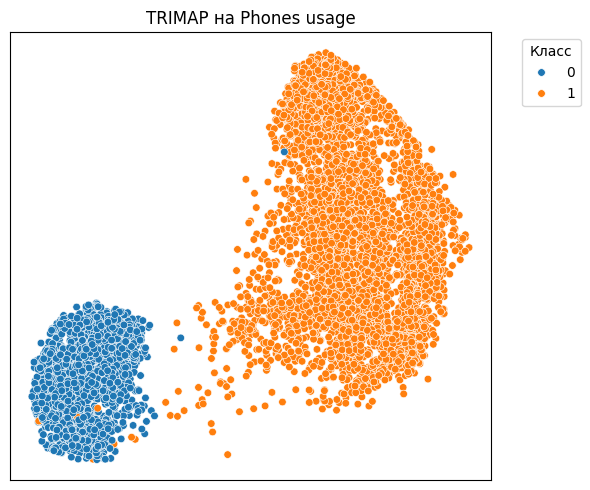

TRIMAP: внутрикласс.=21.356, межкласс.=64.380, ratio=3.015


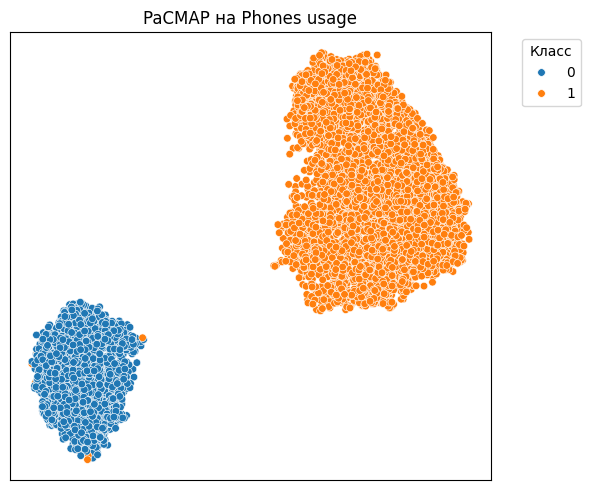

PaCMAP: внутрикласс.=4.622, межкласс.=18.406, ratio=3.982


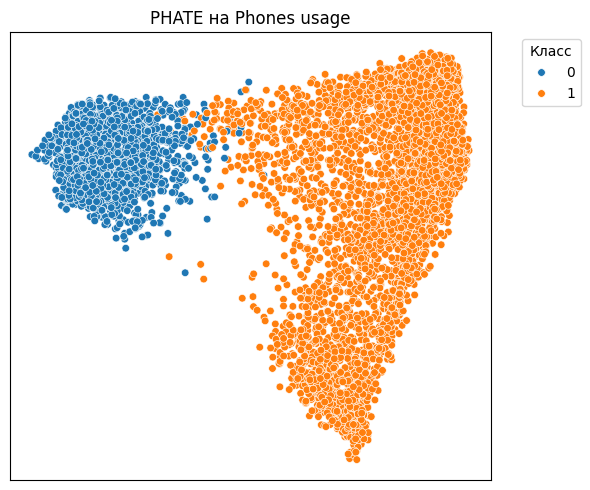

PHATE: внутрикласс.=0.010, межкласс.=0.043, ratio=4.115


In [109]:
X_list = []
names = []

X_tsne_iris = run_tsne(X_own_scaled, random_state=42)
X_list.append(X_tsne_iris); names.append("t-SNE")

X_umap_iris = run_umap(X_own_scaled, random_state=42)
X_list.append(X_umap_iris); names.append("UMAP")

X_trimap_iris = run_trimap(X_own_scaled)
X_list.append(X_trimap_iris); names.append("TRIMAP")

X_pacmap_iris = run_pacmap(X_own_scaled, random_state=42)
X_list.append(X_pacmap_iris); names.append("PaCMAP")

X_phate_iris = run_phate(X_own_scaled, random_state=42)
X_list.append(X_phate_iris); names.append("PHATE")

for X_emb, name in zip(X_list, names):
    plot_embedding(X_emb, y_own, f"{name} на Phones usage")
    same, diff, ratio = separation_score(X_emb, y_own)
    print(
        f"{name}: внутрикласс.={same:.3f}, межкласс.={diff:.3f}, ratio={ratio:.3f}"
    )


Сравнение устойчивости

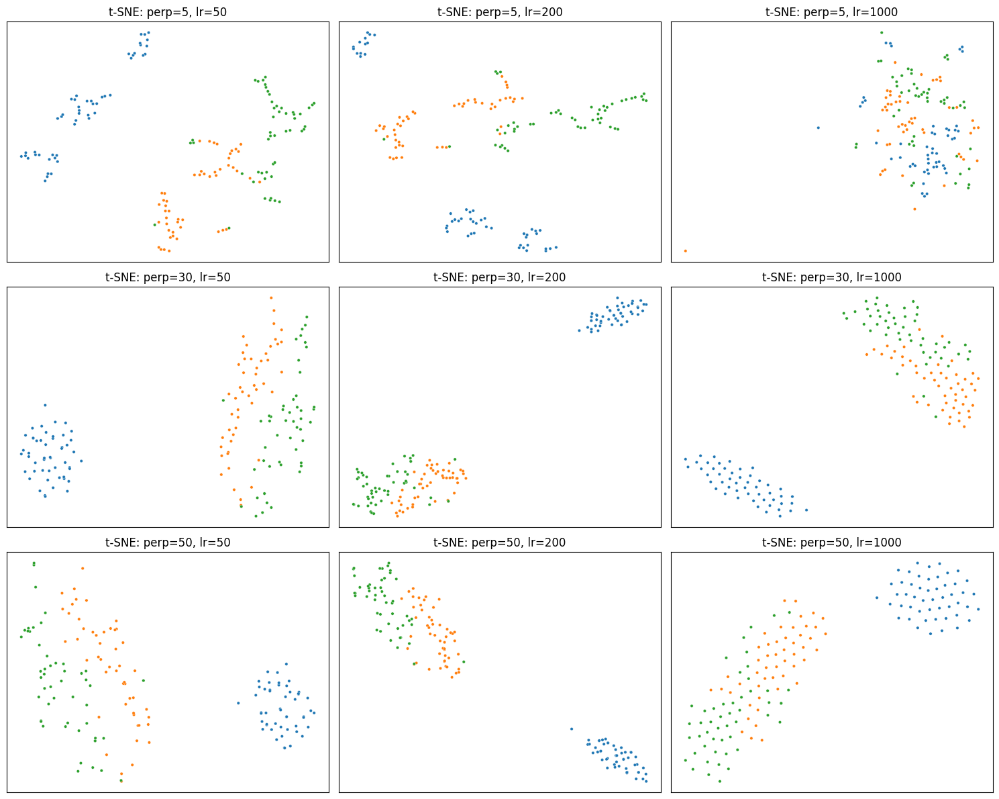

In [110]:
# Iris t-SNE
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        X_emb = run_tsne(X_iris_scaled, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


t-SNE Iris:
1) С увеличением параметра перплексии более заметна разделимость кластеров.
2) Скорость обучения практически ни на что не влияет (с т.зр. разделимости кластеров), хотя плотность кластеров увеличивается

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr

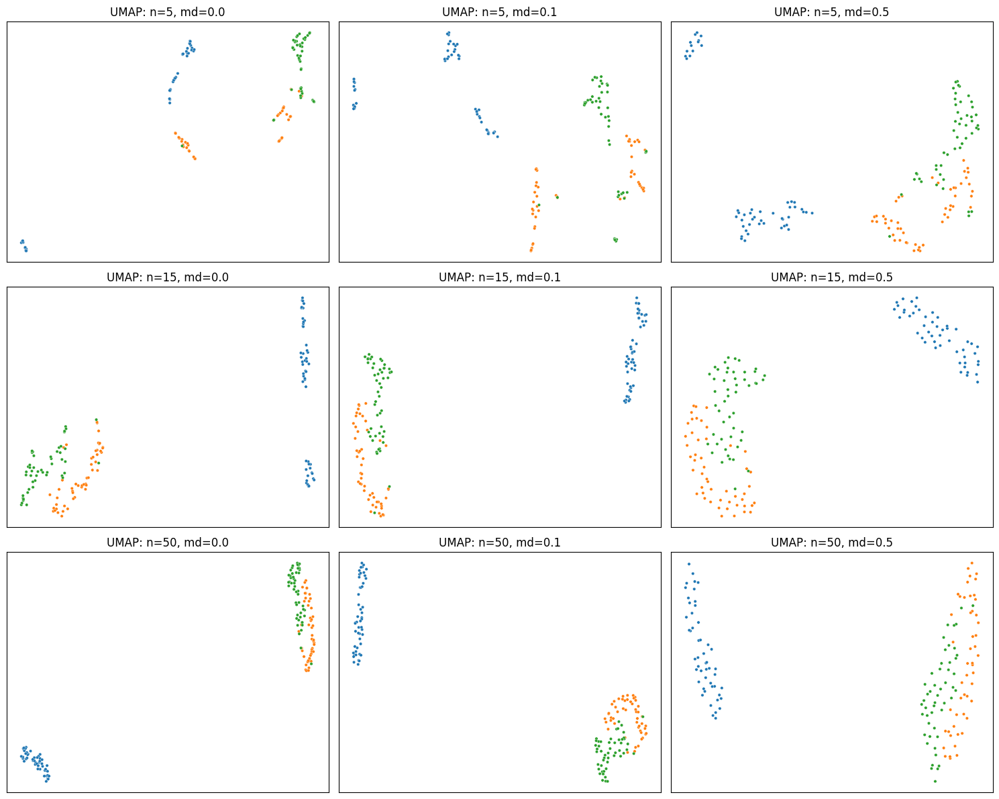

In [111]:
# Iris UMAP
n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        X_emb = run_umap(X_iris_scaled, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"UMAP: n={n}, md={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

UMAP Iris:
1) С увеличением параметра n_neighbors кластеры становятся более плотными и более разделимыми.
2) С увеличением параметра min_dist кластеры становятся более размашистыми.

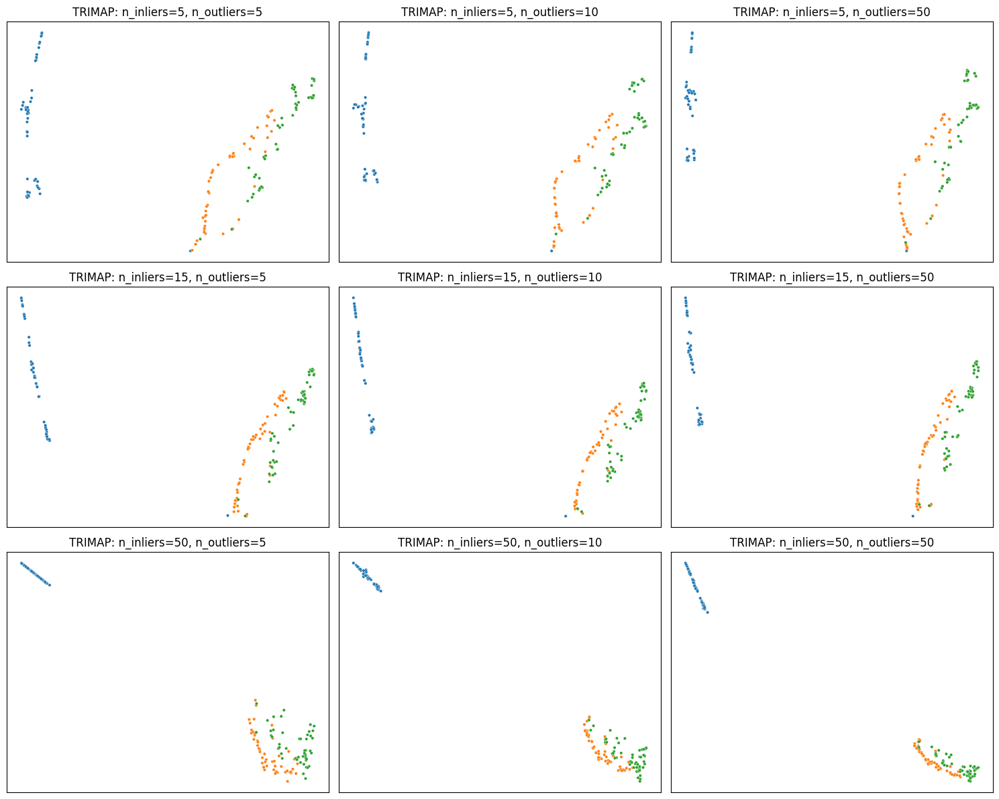

In [112]:
# Iris TriMAP
n_inliers = [5, 15, 50]
n_outliers = [5, 10, 50]

fig, axes = plt.subplots(len(n_inliers), len(n_outliers), figsize=(5*len(n_outliers), 4*len(n_inliers)))

for i, n in enumerate(n_inliers):
    for j, m in enumerate(n_outliers):
        X_emb = run_trimap(X_iris_scaled, n_inliers=n, n_outliers=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"TRIMAP: n_inliers={n}, n_outliers={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

TriMAP Iris:
1) С увеличением параметра n_inliers кластеры становятся более плотными.
2) С увеличением параметра n_outliers кластеры  так же становятся более плотными.

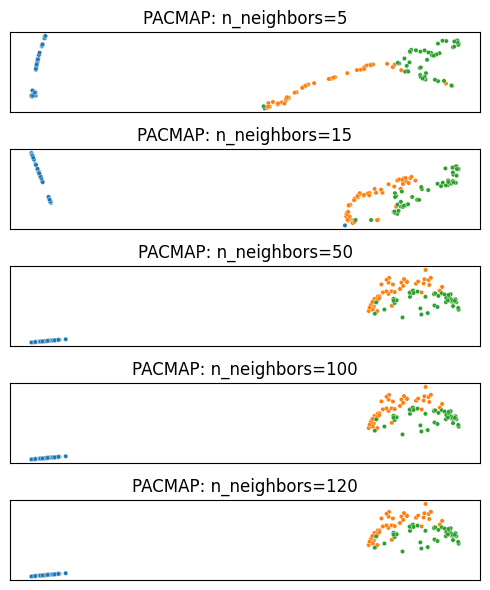

In [113]:
# Iris PaCMAP
n_neighbors = [5, 15, 50, 100, 120]

fig, axes = plt.subplots(len(n_neighbors), figsize=(len(n_neighbors), 6))

for i, n in enumerate(n_neighbors):
    X_emb = run_pacmap(X_iris_scaled, n_neighbors=n)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PACMAP: n_neighbors={n}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

PaCMAP Iris: с увеличением параметра n_neighbors кластеры становятся более плотными и менее разделимыми.

Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
    Calculated affinities in 0.01 seconds.
  Calculated graph and diffusion operator in 0.03 seconds.
  Calculating optimal t...
    Automatically selected t = 27
  Calculated optimal t in 0.03 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...


/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


  Calculated metric MDS in 0.46 seconds.
Calculated PHATE in 0.54 seconds.
Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
    Calculated affinities in 0.02 seconds.
  Calculated graph and diffusion operator in 0.03 seconds.
  Calculating optimal t...
    Automatically selected t = 21
  Calculated optimal t in 0.11 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.02 seconds.
  Calculating metric MDS...


/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by 1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.46 seconds.
Calculated PHATE in 0.66 seconds.
Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
    Calculated affinities in 0.01 seconds.
  Calculated graph and diffusion operator in 0.03 seconds.
  Calculating optimal t...
    Automatically selected t = 19
  Calculated optimal t in 0.02 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.01 seconds.
  Calculating metric MDS...


/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


... (11 outputs left out)

/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


  Calculated metric MDS in 0.35 seconds.
Calculated PHATE in 0.40 seconds.
Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
    Calculated affinities in 0.01 seconds.
  Calculated graph and diffusion operator in 0.03 seconds.
  Calculating optimal t...
    Automatically selected t = 4
  Calculated optimal t in 0.02 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...


/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by -2.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.30 seconds.
Calculated PHATE in 0.37 seconds.


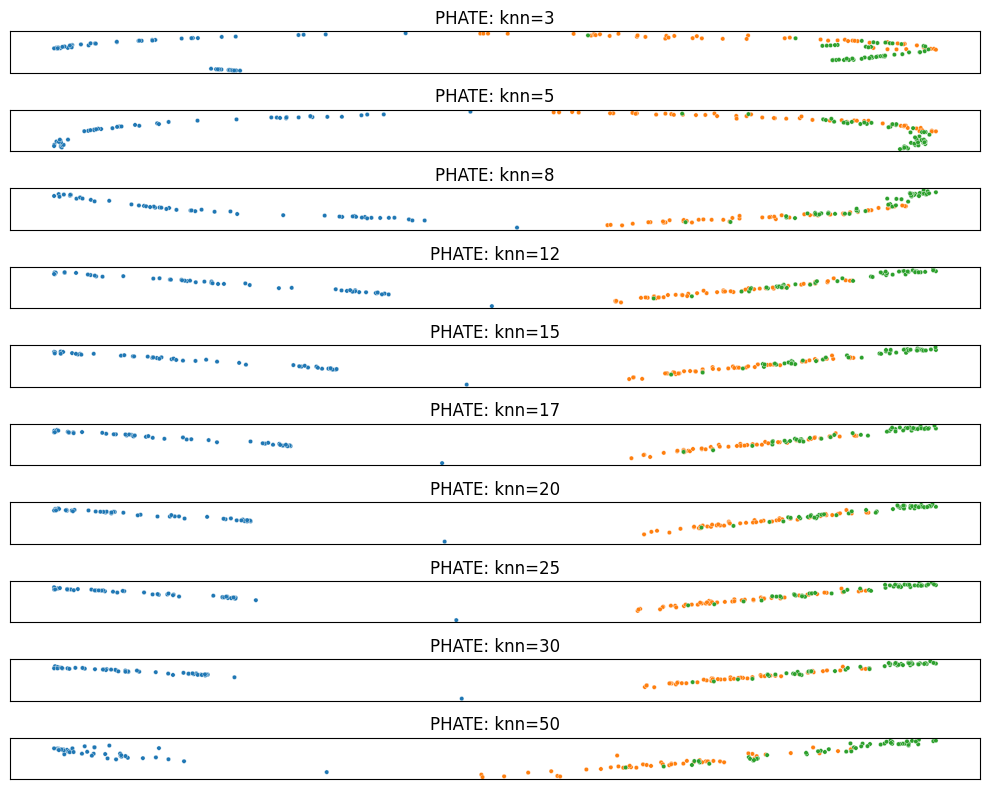

In [124]:
# Iris PHATE
knn = [3, 5, 8, 12, 15, 17, 20, 25, 30, 50]

fig, axes = plt.subplots(len(knn), figsize=(len(knn), 8))

for i, n in enumerate(knn):
    X_emb = run_phate(X_iris_scaled, knn=n)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PHATE: knn={n}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

PHATE Iris: параметр knn практически ни на что не повлиял, плотность и разделимость кластеров не изменились.

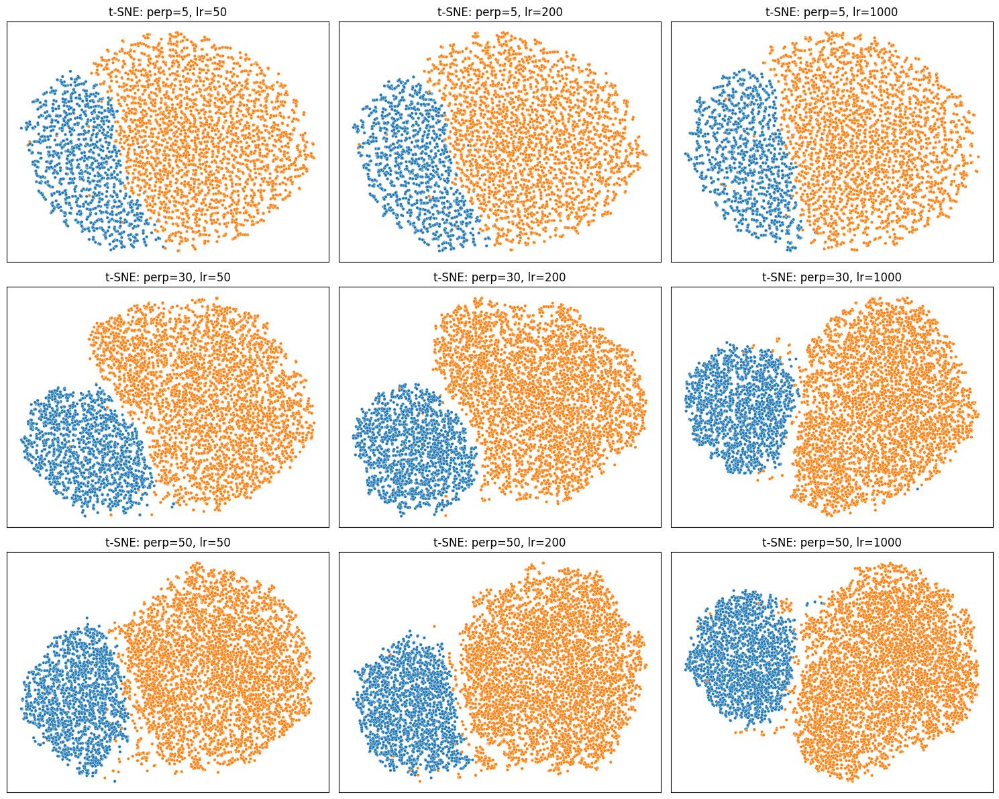

In [115]:
# Phones usage t-SNE
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        X_emb = run_tsne(X_own_scaled, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


t-SNE Phones usage:
1) С увеличением параметра перплексии увеличивается плотность кластеров и более заметна их разделимость.
2) Скорость обучения практически ни на что не влияет.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr

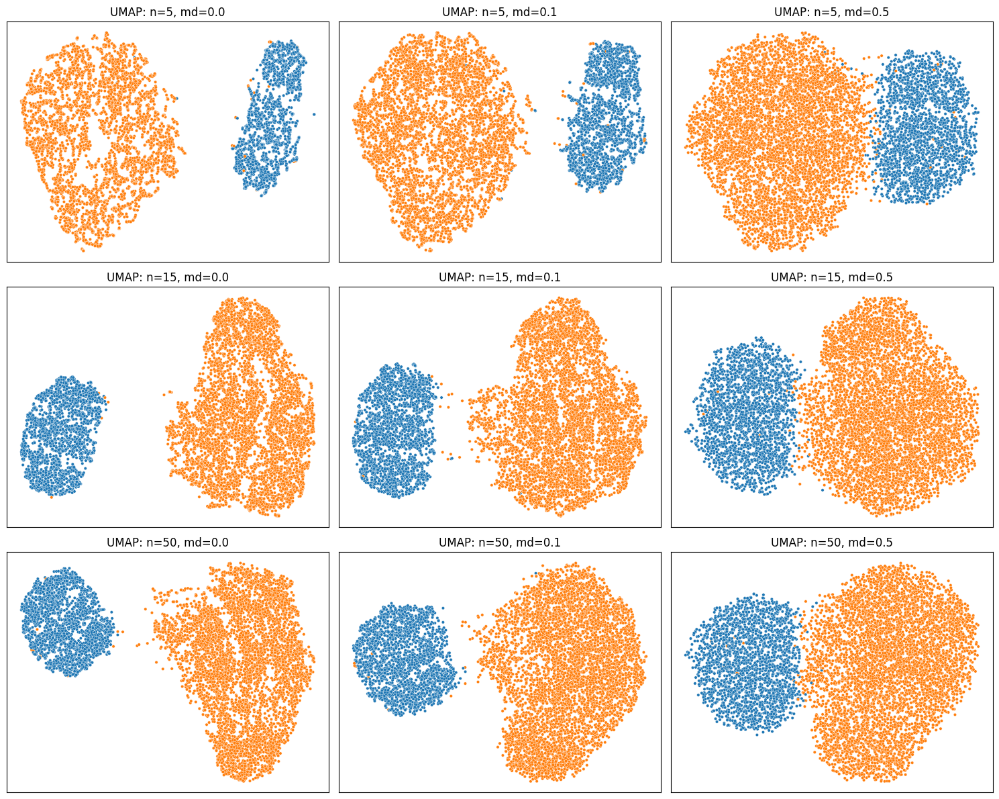

In [116]:
# Phones usage UMAP
n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        X_emb = run_umap(X_own_scaled, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"UMAP: n={n}, md={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

UMAP Phones usage:
1) С увеличением параметра n_neighbors кластеры становятся более плотными.
2) С увеличением параметра min_dist кластеры становятся менее разделимыми.

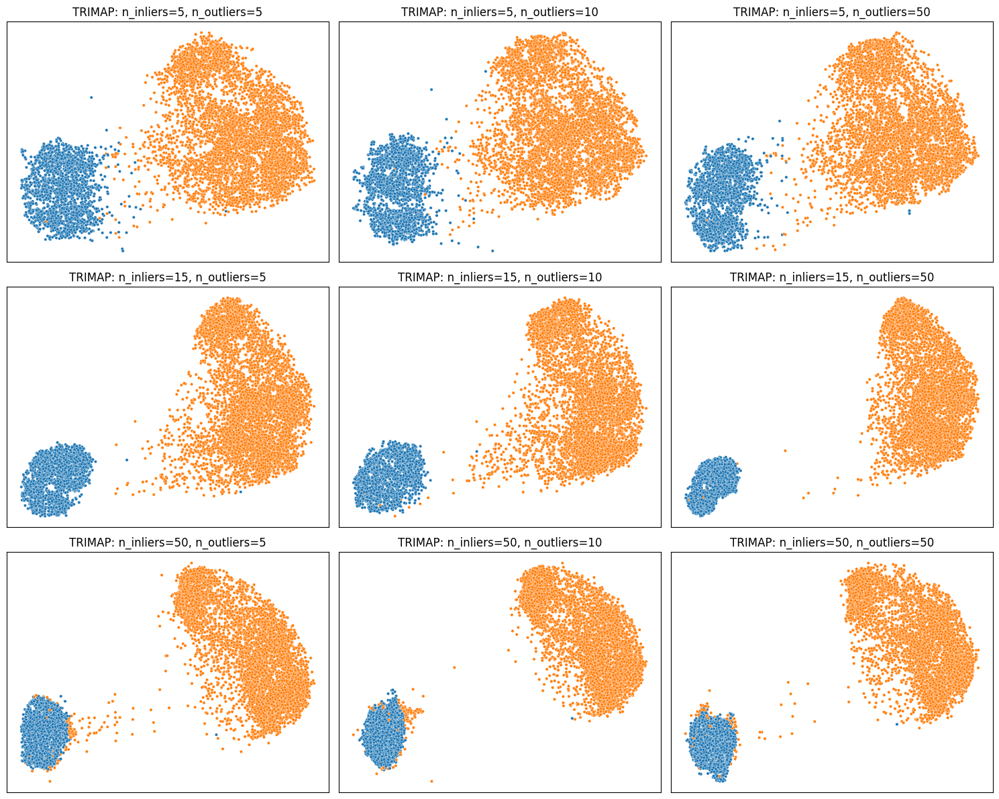

In [117]:
# Phones usage TriMAP
n_inliers = [5, 15, 50]
n_outliers = [5, 10, 50]

fig, axes = plt.subplots(len(n_inliers), len(n_outliers), figsize=(5*len(n_outliers), 4*len(n_inliers)))

for i, n in enumerate(n_inliers):
    for j, m in enumerate(n_outliers):
        X_emb = run_trimap(X_own_scaled, n_inliers=n, n_outliers=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"TRIMAP: n_inliers={n}, n_outliers={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

TriMAP Phones usage:
1) С увеличением параметра n_inliers кластеры становятся более плотными и более разделимыми.
2) С увеличением параметра n_outliers кластеры становятся более разделимыми.

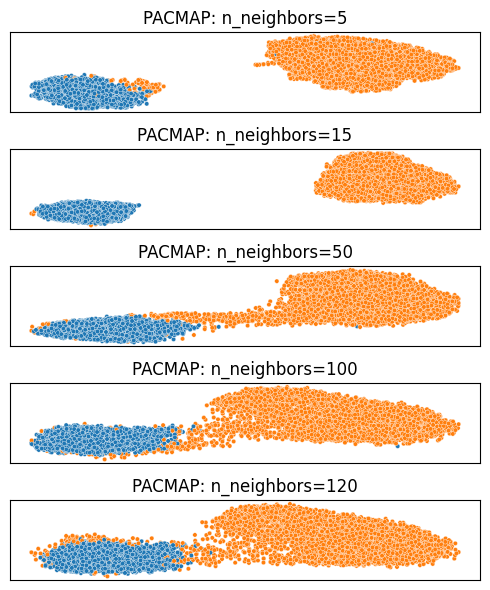

In [118]:
# Phones usage PaCMAP
n_neighbors = [5, 15, 50, 100, 120]

fig, axes = plt.subplots(len(n_neighbors), figsize=(len(n_neighbors), 6))

for i, n in enumerate(n_neighbors):
    X_emb = run_pacmap(X_own_scaled, n_neighbors=n)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PACMAP: n_neighbors={n}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

PaCMAP Phones usage: с увеличением параметра n_neighbors кластеры становятся более размашистыми и менее разделимыми.

Calculating PHATE...
  Running PHATE on 7500 observations and 11 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 2.66 seconds.
    Calculating affinities...
    Calculated affinities in 0.43 seconds.
  Calculated graph and diffusion operator in 3.12 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 1.57 seconds.
    Calculating KMeans...
    Calculated KMeans in 28.58 seconds.
  Calculated landmark operator in 30.16 seconds.
  Calculating optimal t...
    Automatically selected t = 49
  Calculated optimal t in 7.63 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 5.97 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 2.3% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 5.47 seconds.
Calculated PHATE in 54.59 seconds.
Calculating PHATE...
  Running PHATE 

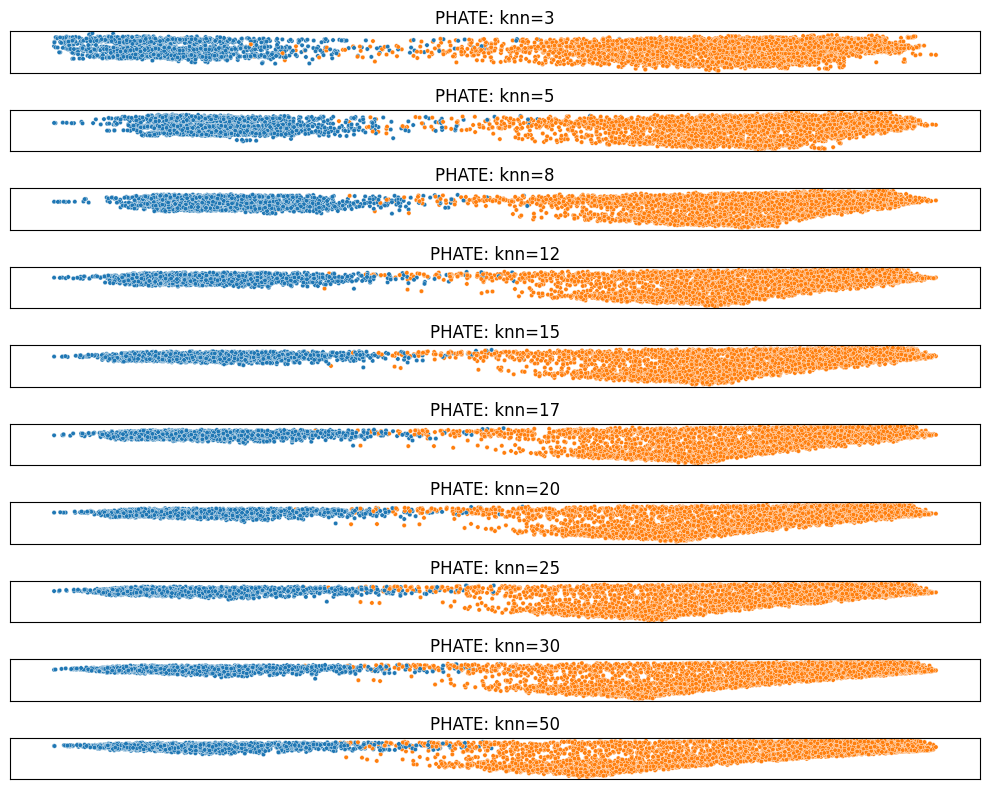

In [126]:
# Phones usage PHATE
knn = [3, 5, 8, 12, 15, 17, 20, 25, 30, 50]

fig, axes = plt.subplots(len(knn), figsize=(len(knn), 8))

for i, n in enumerate(knn):
    X_emb = run_phate(X_own_scaled, knn=n)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PHATE: knn={n}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

PHATE Phones usage: параметр knn практически ни на что не повлиял, плотность и разделимость кластеров не изменились.

Обычно структура UMAP меняется плавнее, кластеры остаются узнаваемыми при разумном диапазоне параметров.

*Задача* Аналогично нужно сделать по одной строке графиков для TriMAP, PaCMAP, PHATE с варьированием ключевого параметра (количество соседей или похожий гиперпараметр) и показать, насколько устойчив рисунок.



| Метод  | Скорость на больших данных                   | Локальное разделение              | Глобальная структура                            | Чувствительность к параметрам                         | Комментарий                                        |
| ------ | -------------------------------------------- | --------------------------------- | ----------------------------------------------- | ----------------------------------------------------- | -------------------------------------------------- |
| t‑SNE  | Низкая l                    | Отличное                   | Слабая                                   | Высокая (perplexity, lr, random_state) aicompetence+2 | Хорошо для локальных кластеров, тяжёлый тюнинг     |
| UMAP   | Высокая l                   | Очень хорошее   | Лучшая, чем у t‑SNE           | Ниже, чем у t‑SNE aicompetence+2                      | Хороший баланс локал/глобал, удобен в практике     |
| TriMAP | Средняя                              | Хорошее                   | Сильный упор на глобальную структуру    | Умеренная                                     | Лучше показывает относительное положение кластеров |
| PaCMAP | Средняя                               | Отличное                   | Хорошее                                  | Умеренная                                      | Часто даёт чёткие кластеры и форму многобразия     |
| PHATE  | Средняя/низкая (зависит от размера)   | Хорошее        | Очень хорошее, особенно для траекторий   | Умеренная                          | Сильный метод для непрерывных переходов            |

# Варианты препроцессинга
*Задача* — явно сравнить, как UMAP и t‑SNE реагируют на разные варианты нормировки и отбора признаков.

## Определяем три сценария
Без масштабирования (сырой набор признаков).

StandardScaler (z‑нормировка).

MinMaxScaler + отбор признаков по дисперсии (эмуляция feature selection).

Задание. Проделать все три сценария. Обучить все модели при разных сценария кластеризации.
Нужно в результате:
1. описать, какие признаки были отброшены и почему это может влиять на качество кластеризации во вложенном пространстве.
1. сравнить вычислительное время и сделать вывод о масштабируемости методов
1. изменить гиперпараметры (perplexity, n_neighbors, min_dist) и исследовать совместное влияние гиперпараметров и препроцессинга на структуру кластеров.


In [120]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import VarianceThreshold

X_own_scaled_minmax = MinMaxScaler().fit_transform(X_own)

selector = VarianceThreshold(threshold=0.085)
few_X_own_scaled_minmax = selector.fit_transform(X_own_scaled_minmax)

In [121]:
selected_indices = np.where(selector.get_support())[0]
dropped_indices = np.where(~selector.get_support())[0]

In [122]:
feature_names = df.columns.tolist()

selected_features = [feature_names[i] for i in selected_indices]
dropped_features = [feature_names[i] for i in dropped_indices]

print("Оставленные признаки:", selected_features)
print("Отброшенные признаки:", dropped_features)

Оставленные признаки: ['age', 'app_opens_per_day', 'addicted_label', 'stress_map']
Отброшенные признаки: ['daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'weekend_screen_time']


При threshold=0.085 были отброшены признаки:
1) 'daily_screen_time_hours' - время (в часах) ежедневного использования телефона;
2) 'social_media_hours' - время (в часах), потраченное на социальные сети;
3) 'gaming_hours' - время (в часах), потраченное на игры;
4) 'work_study_hours' - время (в часах), потраченное на работу и обучение;
5) 'sleep_hours' - время (в часах), потраченное на сон;
6) 'notifications_per_day' - количество уведомлений, которые приходят за день;
7) 'weekend_screen_time' - время использования телефона в выходные.

In [123]:
import datetime

Raw data


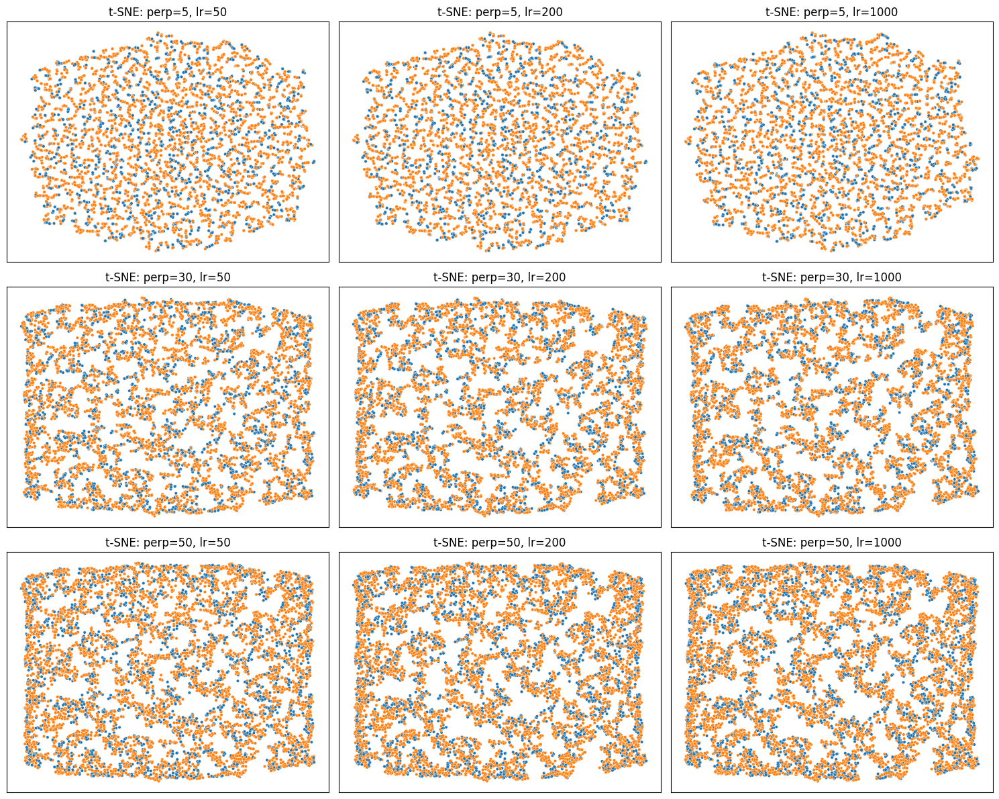

Time work: 0:16:15.673521


In [ ]:
# t-SNE + Raw data

perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

print('Raw data')

startTime = datetime.datetime.now()

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        X_emb = run_tsne(X_own, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

endTime = datetime.datetime.now()
print('Time work:', endTime - startTime)

Сырые данные вообще не разделились на кластеры, все вперемешку.

StandardScaler


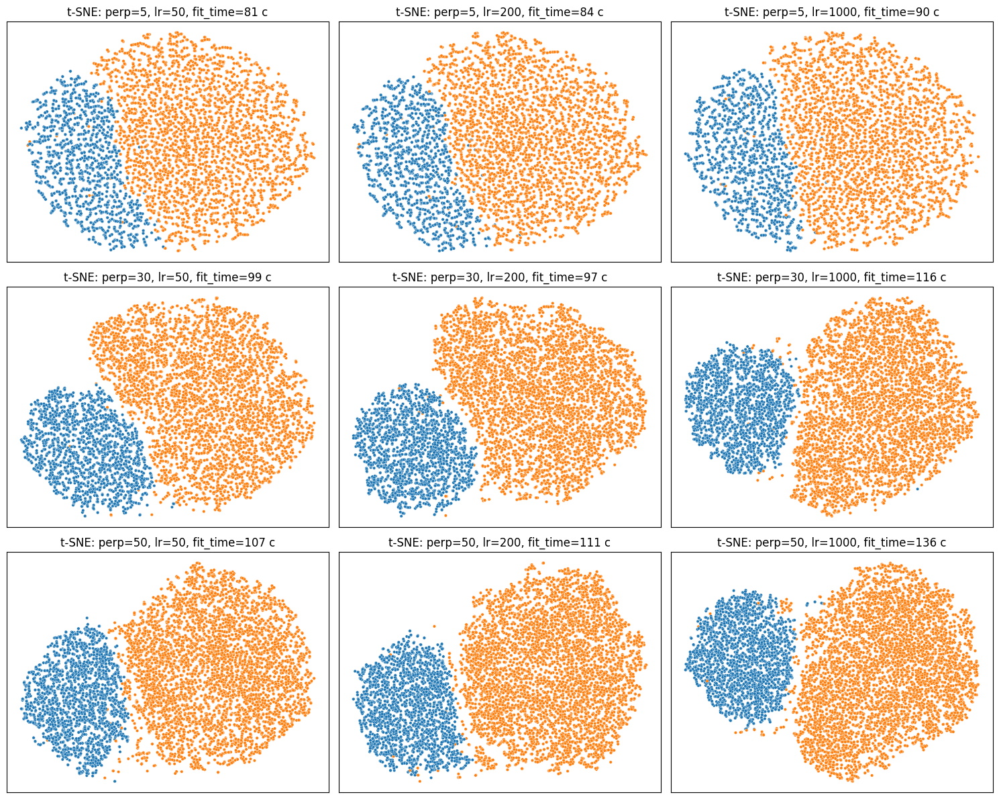

Time work: 0:02:18.977475


In [ ]:
# t-SNE + StandardScaler

perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

print('StandardScaler')

startTime = datetime.datetime.now()

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        startTime = datetime.datetime.now()
        X_emb = run_tsne(X_own_scaled, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        endTime = datetime.datetime.now()
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}, fit_time={(endTime-startTime).seconds} с")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

endTime = datetime.datetime.now()
print('Time work:', endTime - startTime)

t-SNE StandardScaler:
1) С увеличением параметра перплексии увеличивается плотность кластеров и более заметна их разделимость.
2) Скорость обучения практически ни на что не влияет.

MinMaxScaler + feature selection


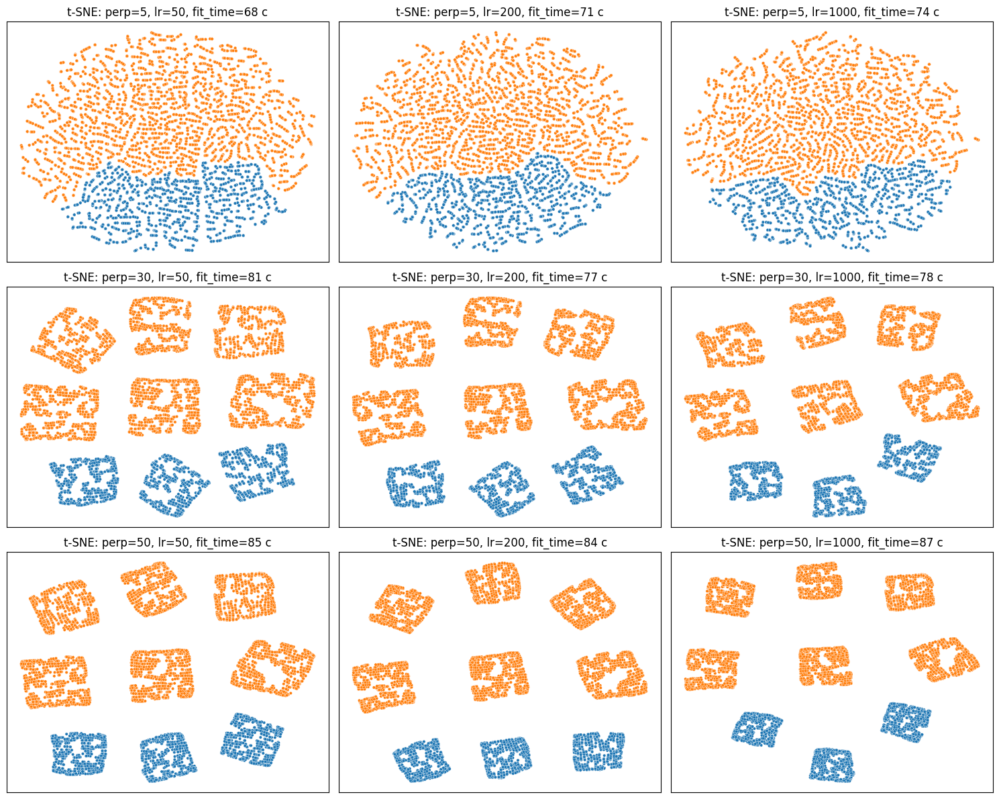

Time work: 0:01:28.857397


In [ ]:
# t-SNE + MinMaxScaler + feature selection

perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

print('MinMaxScaler + feature selection')

startTime = datetime.datetime.now()

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        startTime = datetime.datetime.now()
        X_emb = run_tsne(few_X_own_scaled_minmax, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        endTime = datetime.datetime.now()
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}, fit_time={(endTime-startTime).seconds} c")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

endTime = datetime.datetime.now()
print('Time work:', endTime - startTime)

t-SNE MinMaxScaler:
1) С увеличением параметра перплексии увеличивается плотность кластеров и более заметна их разделимость. Также можно наблюдать странное разделение данных в группы внутри самих кластеров, но непонятно, с чем это связано.
2) Скорость обучения практически ни на что не влияет.

Raw data
Сырые данные:


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr

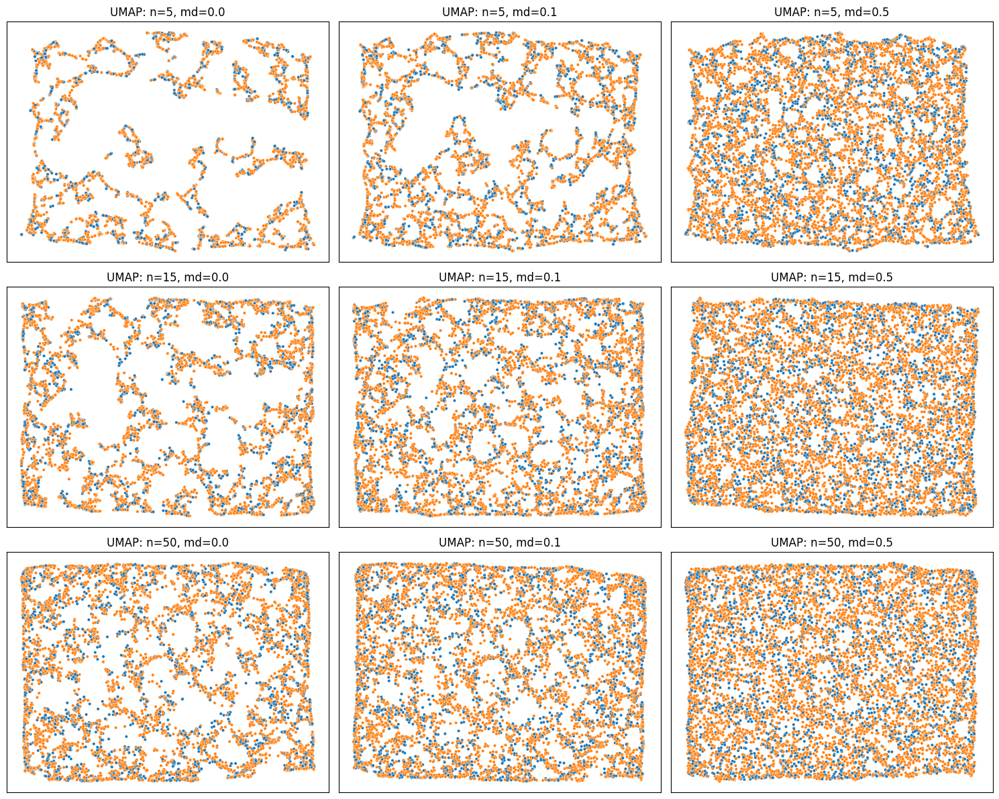

Time work: 0:02:48.554584


In [93]:
# UMAP + Raw data

n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

print('Raw data')

startTime = datetime.datetime.now()

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

print('Сырые данные:')
for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        X_emb = run_umap(X_own, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"UMAP: n={n}, md={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

endTime = datetime.datetime.now()
print('Time work:', endTime - startTime)

Сырые данные вообще не разделились на кластеры, все вперемешку.

StandardScaler


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr

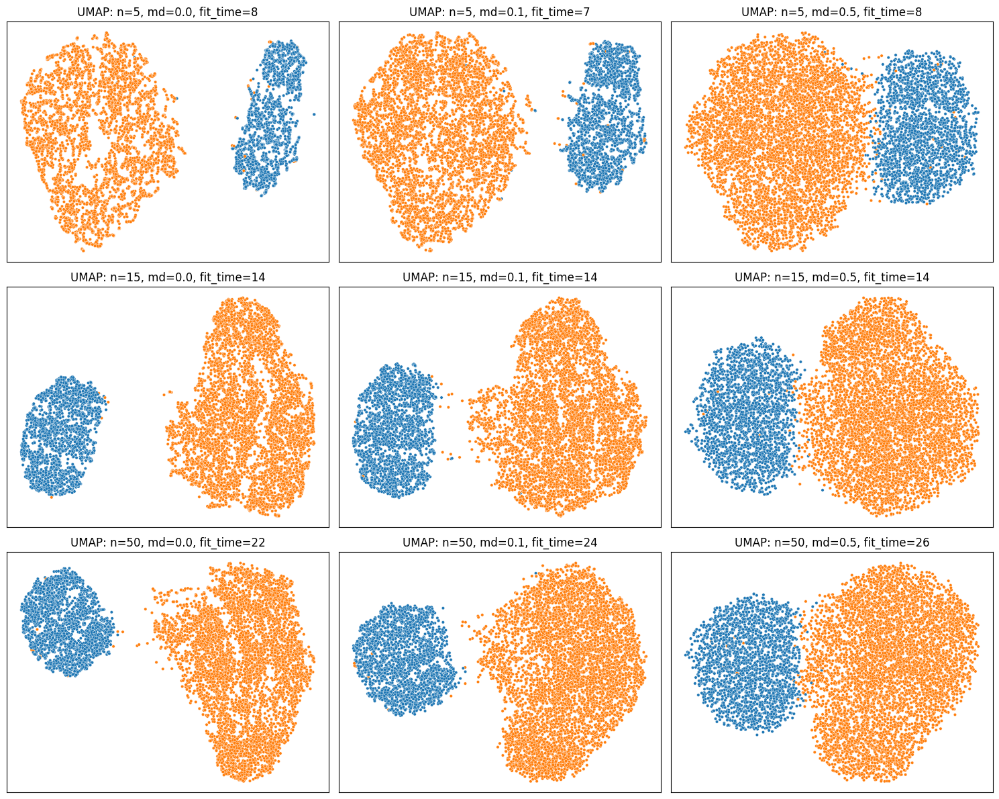

In [ ]:
# UMAP + StandardScaler

n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

print('StandardScaler')

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        startTime = datetime.datetime.now()
        X_emb = run_umap(X_own_scaled, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        endTime = datetime.datetime.now()
        ax.set_title(f"UMAP: n={n}, md={m}, fit_time={(endTime-startTime).seconds}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


UMAP StandardScaler:
1) С увеличением параметра n_neighbors кластеры становятся более плотными.
2) С увеличением параметра min_dist кластеры становятся менее разделимыми.

MinMaxScaler + feature selection


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr

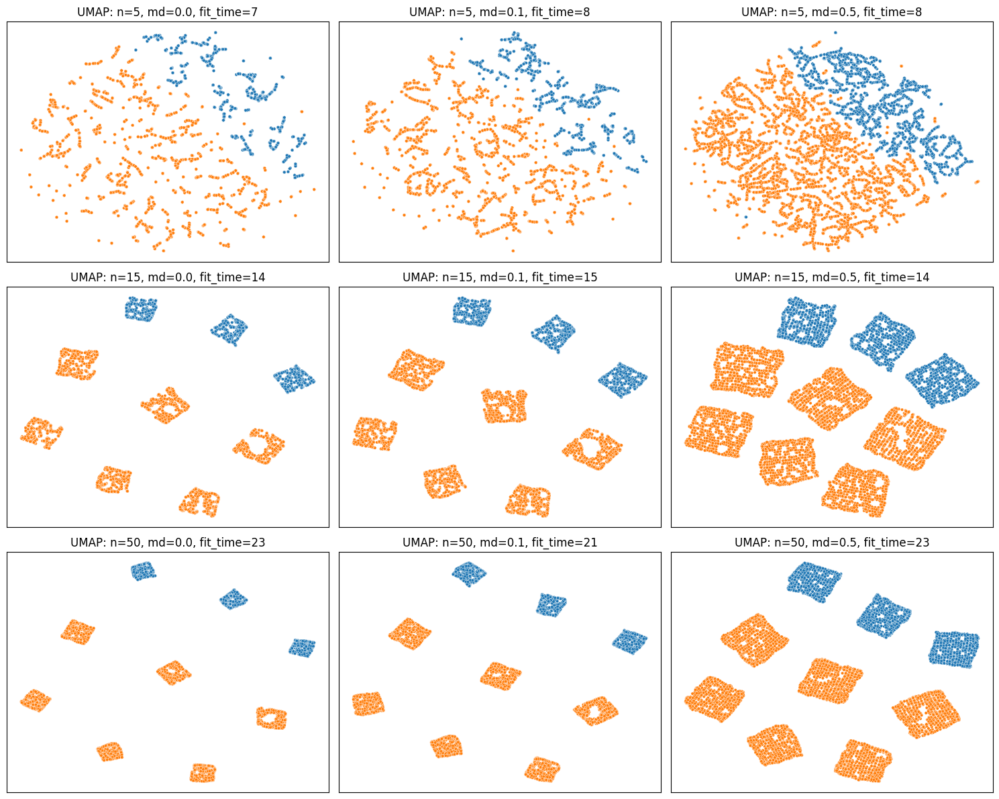

In [ ]:
# UMAP + MinMaxScaler + feature selection

n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

print('MinMaxScaler + feature selection')

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        startTime = datetime.datetime.now()
        X_emb = run_umap(few_X_own_scaled_minmax, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        endTime = datetime.datetime.now()
        ax.set_title(f"UMAP: n={n}, md={m}, fit_time={(endTime-startTime).seconds}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

UMAP MinMaxScaler:
1) С увеличением параметра n_neighbors кластеры становятся более плотными и разделимыми. Также можно наблюдать странное разделение данных в группы внутри самих кластеров, но непонятно, с чем это связано.
2) С увеличением параметра min_dist кластеры становятся менее разделимыми.